# Onafhankelijke E2-schaal · vijfepochpilot
## CNN-8 / SVHN · E4M3 → E2M3 → E2M1 · A32 · B32

**Onderzoeksvraag:** kan één zelfstandig geleerde absolute shared scale voor de E2-formaten de gezamenlijke training ondersteunen, zonder een vaste verhouding of een menu van tien verhoudingen tegenover E4 op te leggen?

De E4-bronschaal volgt de bestaande amax-regel. **E2M3 en E2M1 delen een tweede E8M0-schaal per groep.** De lagere elementcodes blijven uit de E4-broncodes afgeleid via exponenttruncatie en daarna mantissatruncatie. De initialisatie is numeriek gelijk aan ×64, maar die relatie wordt daarna niet behouden of opnieuw berekend.

Deze notebook leest uitsluitend opgeslagen JSON/CSV-bestanden. Zij start geen training, laadt geen modelcheckpoints en verandert geen onderzoeksdata. Grafieken worden pas opgeslagen wanneer `SAVE_FIGURES = True`; dat maakt een nieuwe map.

In [18]:
from pathlib import Path
RUN_DIR = Path('C:\\Users\\renzo\\master-thesis-mx\\mx_runs\\mx_triple_independent_e2_scale_pilot5\\20261111_165230_352318_joint_run')
SAVE_FIGURES = False


In [19]:
import importlib.util
import sys
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

package_name = "mx_triple_independent_e2_scale_pilot5_v1"
candidates = ([Path(RUN_DIR)] if RUN_DIR is not None else []) + [Path.cwd()]
for base in [Path.cwd(), *list(Path.cwd().parents)[:4]]:
    candidates.append(base / "software_checks" / package_name)
helper_path = next((p / "notebook_support.py" for p in candidates if (p / "notebook_support.py").is_file()), None)
if helper_path is None:
    raise FileNotFoundError("notebook_support.py ontbreekt. Open de notebook vanuit de pakket- of resultatenmap, of vul RUN_DIR in.")
spec = importlib.util.spec_from_file_location("mx_independent_notebook_support", helper_path)
h = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = h
spec.loader.exec_module(h)
run = h.load_run(RUN_DIR)
figures = {}
display(Markdown(h.status_markdown(run)))
display(h.diagnostics_table(run))

**Status: PASS.** 5 van maximaal 5 epochs beschikbaar. Pilot volledig en consistent.

**Gelezen resultatenmap:** `C:\Users\renzo\master-thesis-mx\mx_runs\mx_triple_independent_e2_scale_pilot5\20261111_165230_352318_joint_run`

E4M3 behoudt zijn actuele amax-schaal. E2M3 en E2M1 delen één absolute geleerde E8M0-schaal per groep. Alleen bij initialisatie is deze precies ×64 ten opzichte van E4. Daarna wordt de lagere schaal uitsluitend uit de eigen parameter φ bepaald.

,Niveau,Melding
0,RUNWAARSCHUWING,The argument 'device' of Tensor.pin_memory() i...
1,RUNWAARSCHUWING,The argument 'device' of Tensor.is_pinned() is...


## 1. Wat verandert precies?

Voor groep $g$ op tijdstip $t$ is de bestaande E4-schaal $S_4(g,t)=2^{e_4(g,t)}$. De nieuwe parameter is een **absolute log₂-schaal**:

$$\phi(g,0)=e_4(g,0)+6,\qquad e_2(g,t)=\lfloor\phi(g,t)\rfloor+\mathbf{1}\!\left[\phi(g,t)-\lfloor\phi(g,t)\rfloor\geq\tfrac12\right],\qquad S_2(g,t)=2^{e_2(g,t)}.$$

De relatie met de actuele bron, $\Delta(g,t)=e_2(g,t)-e_4(g,t)$ en $S_2/S_4=2^\Delta$, is vervolgens **een geobserveerde uitkomst**. Zij is niet de getrainde parameter en is niet tot de vroegere tien keuzes begrensd. De absolute E2-schaal blijft bij een onveranderde φ gelijk, ook wanneer de E4-bronschaal verandert. De lagere **elementcodes** blijven wel van de E4-bron afhangen.

Het FP32-hulpparameterbereik is [−127,127]. De hard-forward gebruikt alleen een E8M0-schaal (geen extra mantissa). Niet elke combinatie van een hoge E8M0-exponent en een E2-elementwaarde blijft eindig in FP32; de uitvoering geeft dan een expliciete fout en clipt dit niet stilzwijgend.

**Implementatiebronnen:** `PROTOCOL.md`, `run_train.py`, `trunc_adapter.py` en `trunc_support.py` in dit pakket. Dit is een verkennende, nieuwe proefopzet; het is nog geen bewezen accuracyverbetering.

In [20]:
display(h.protocol_table(run))

,Onderdeel,Afspraak
0,Model / dataset,"CNN-8 (svhnq, expand=2) / SVHN train + test; g..."
1,Precisies,E4M3 → E2M3 → E2M1; alle activaties A32
2,Masters / optimizer,FP32; Adam; drie recursieve distillatiepasses ...
3,Groepen,B32; per outputkanaal; 4.080 groepen in zes MX...
4,E4-schaal,Bestaande amax-regel; verandert met gewichten;...
5,E2-schaal,Absoluut S₂=2^round_half_up(φ); E2M3 en E2M1 d...
6,Initialisatie,"Eenmalig φ₀=e₄,₀+6; daarna geen vaste of beper..."
7,Exponentcodes,E4M3: s e3 e2 e1 e0 m2 m1 m0 → E2M3: s e3 e2 m...
8,Mantissacodes,E2M1-code = E2M3-code >> 2; dezelfde onafhanke...
9,Schaalgradient,ln(2)·Σ(gradient_q · q) per echte groep; som v...


## 2. Accuracyverloop en historische vergelijkingen

Alle grafieken gebruiken de volledige beschikbare pilotgeschiedenis. De accuracy-as zoomt in op het relevante bereik en bevat **alle getoonde waarden**; eventuele lage accuracies worden dus niet verborgen.

De vaste ×64-referentie en de tienkeuzereferentie zijn eerdere, afzonderlijke trainingen. Voor alle drie de varianten worden uitsluitend dezelfde eerste epochs getoond. Er wordt geen nieuwe pilot met een epoch100-eindscore vergeleken.

In [21]:
display(Markdown(h.comparison_markdown(run)))

Vergeleken worden exact epochs **1–5** van de nieuwe pilot, Vaste verhouding ×64 en 10 relatieve keuzes · start ×64. De vaste ×64-reeks komt uit de **eerste vijf epochs van een eerdere 100-epochrun**; de relatieve tienkeuzereeks uit de eerdere vijfepochpilot. De baselinebestanden zijn ongewijzigd en op hash gecontroleerd.

De basisinitialisatie en genoemde trainingsinstellingen zijn gecontroleerd; voor de tienkeuzereferentie is ook de opgeslagen samplevolgorde gecontroleerd. Voor de vaste referentie is geen volledige history in dit pakket aanwezig. Dit zijn historische individuele runs, met de oorspronkelijke niet-bitexacte CUDA-backend. Kleine verschillen bewijzen daarom geen statistisch significant voordeel. De onafhankelijke parametrisatie verandert ook hoe de lagere schaal op veranderingen in de E4-bronschaal reageert.

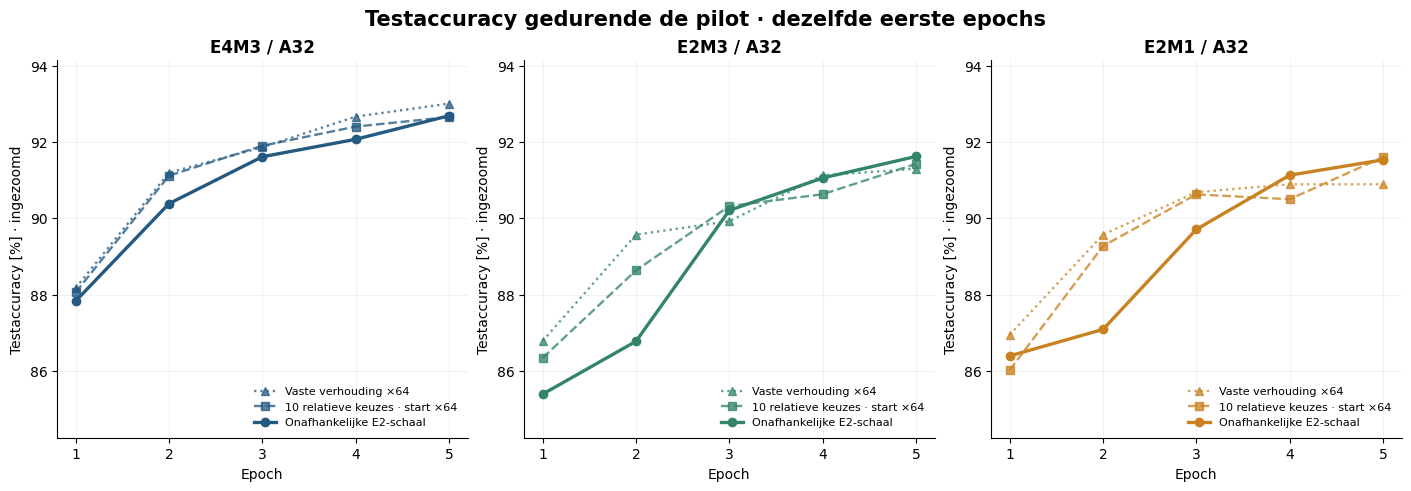

In [22]:
fig = h.plot_learning(run)
figures["01_accuracy_verloop"] = fig
display(fig)
plt.close(fig)

### Laatste epoch en selectie op beste E4M3

Links staat de laatste **gemeenschappelijke** epoch, normaal epoch5. Rechts kiest elke variant de eerste hoogste E4M3-testaccuracy binnen hetzelfde beschikbare venster (maximaal de eerste vijf epochs); E2M3 en E2M1 komen steeds uit diezelfde epoch.

Bij de nieuwe pilot verwijst de selectie naar het opgeslagen best/last-checkpoint. Bij de historische vaste ×64-run is de selectie binnen de eerste vijf epochs hier uit de metrics afgeleid; zij is **niet** het beste checkpoint van de volledige 100-epochrun. Selectie op de officiële testset maakt deze beste score geen onafhankelijke testschatting.

In [23]:
display(Markdown("**Laatste gemeenschappelijke epoch**"))
display(h.checkpoint_table(run, "last").round(4))
display(Markdown("**Beste E4M3 binnen hetzelfde venster**"))
display(h.checkpoint_table(run, "best").round(4))
display(Markdown("**Verschil op het gemeenschappelijke eindpunt** — procentpunten en aantallen testbeelden"))
display(h.difference_table(run).round(4))

**Laatste gemeenschappelijke epoch**

,Variant,Epoch,Selectie,E4M3 testaccuracy [%],E4M3 correct,E2M3 testaccuracy [%],E2M3 correct,E2M1 testaccuracy [%],E2M1 correct
0,Vaste verhouding ×64,5,gemeenschappelijk eindpunt,93.0086,24212,91.2992,23767,90.8920,23661
1,10 relatieve keuzes · start ×64,5,gemeenschappelijk eindpunt,92.6552,24120,91.4259,23800,91.6026,23846
2,Onafhankelijke E2-schaal,5,gemeenschappelijk eindpunt,92.6898,24129,91.6219,23851,91.5335,23828


**Beste E4M3 binnen hetzelfde venster**

,Variant,Epoch,Selectie,E4M3 testaccuracy [%],E4M3 correct,E2M3 testaccuracy [%],E2M3 correct,E2M1 testaccuracy [%],E2M1 correct
0,Vaste verhouding ×64,5,eerste beste E4 in beschikbaar venster,93.0086,24212,91.2992,23767,90.8920,23661
1,10 relatieve keuzes · start ×64,5,eerste beste E4 in beschikbaar venster,92.6552,24120,91.4259,23800,91.6026,23846
2,Onafhankelijke E2-schaal,5,eerste beste E4 in beschikbaar venster,92.6898,24129,91.6219,23851,91.5335,23828


**Verschil op het gemeenschappelijke eindpunt** — procentpunten en aantallen testbeelden

,Epoch,Referentie,Precisie,Onafhankelijk [%],Referentie [%],Verschil [procentpunt],Verschil correct [beelden]
0,5,Vaste verhouding ×64,E4M3,92.6898,93.0086,-0.3188,-83
1,5,Vaste verhouding ×64,E2M3,91.6219,91.2992,0.3227,84
2,5,Vaste verhouding ×64,E2M1,91.5335,90.8920,0.6415,167
3,5,10 relatieve keuzes · start ×64,E4M3,92.6898,92.6552,0.0346,9
4,5,10 relatieve keuzes · start ×64,E2M3,91.6219,91.4259,0.1959,51
5,5,10 relatieve keuzes · start ×64,E2M1,91.5335,91.6026,-0.0691,-18


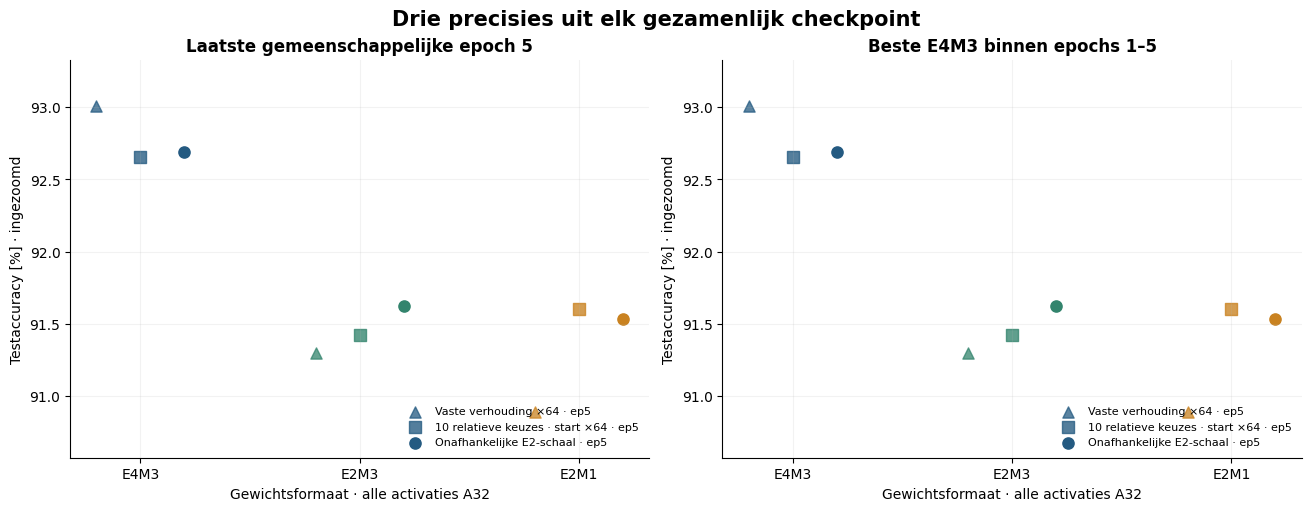

In [24]:
fig = h.plot_checkpoints(run)
figures["02_gemeenschappelijke_checkpoints"] = fig
display(fig)
plt.close(fig)

## 3. Welke schalen ontstaan?

Deze sectie scheidt de **geleerde absolute E2-exponent** van de **geobserveerde verhouding tot de bewegende E4-bronschaal**. Een verandering van die verhouding kan zowel door E2-leren als door een gewijzigde E4-bronschaal ontstaan.

De eerste grafiek vergelijkt initialisatie (epoch0) met de laatste beschikbare epoch. Daarna volgt de verdeling per epoch. Alle waargenomen verhoudingen worden getoond, ook waarden buiten de vroegere ×1…×512. Een niet-waargenomen waarde binnen een histogram betekent nul groepen; ontbrekende schaaldata worden nooit door nul vervangen.

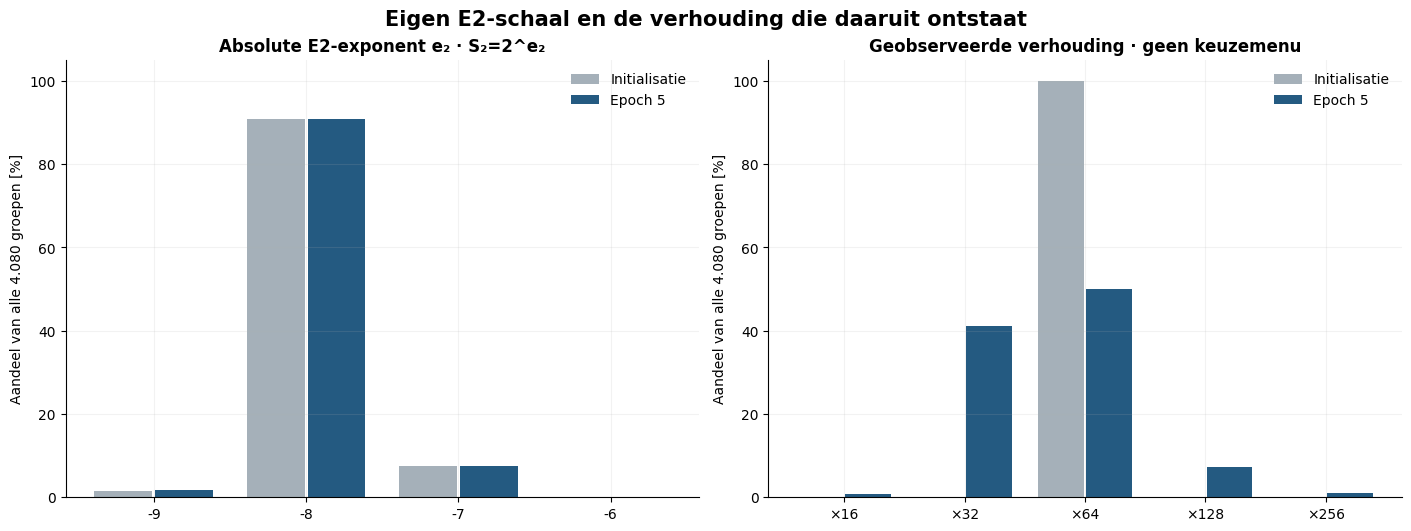

,Epoch,Geobserveerde Δ=e₂−e₄,Verhouding S₂/S₄,Groepen,Aandeel [%]
0,5,4,×16,29,0.7108
1,5,5,×32,1678,41.1275
2,5,6,×64,2039,49.9755
3,5,7,×128,293,7.1814
4,5,8,×256,41,1.0049


In [25]:
fig = h.plot_scale_distributions(run)
figures["03_schaalverdelingen_init_eind"] = fig
display(fig)
plt.close(fig)
display(h.scale_distribution_table(run).round(4))

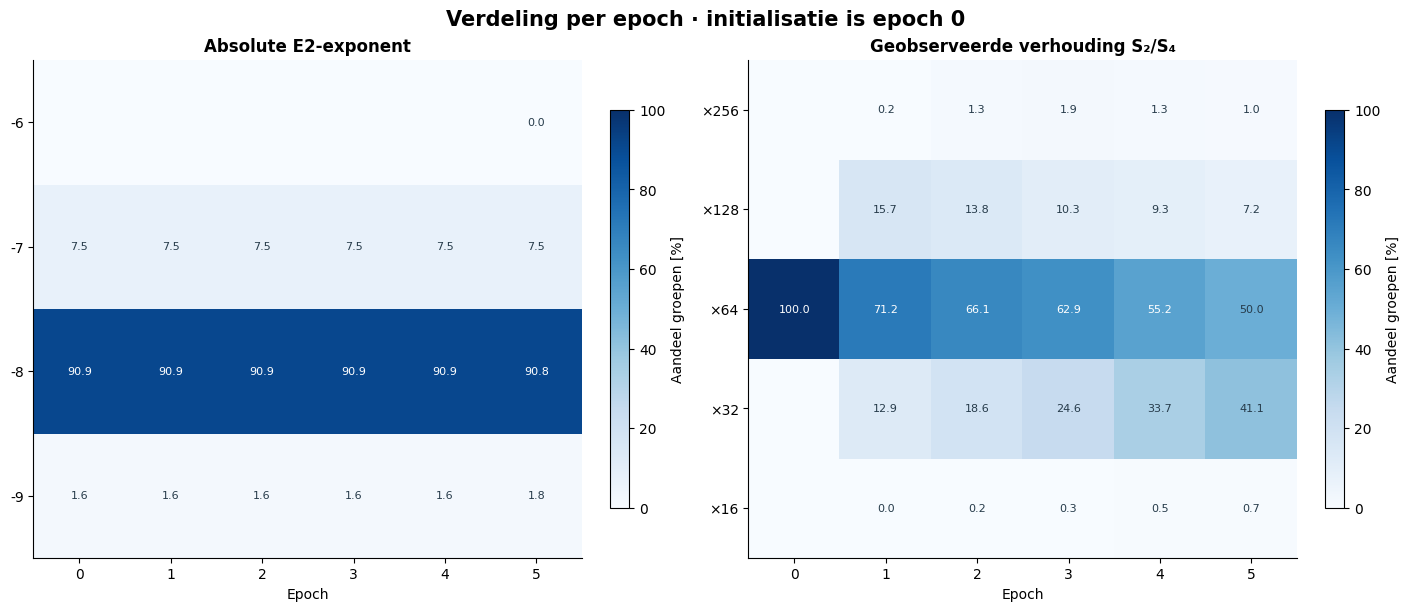

In [26]:
fig = h.plot_scale_evolution(run)
figures["04_schaalverdelingen_per_epoch"] = fig
display(fig)
plt.close(fig)

### Laagverschillen

De volgende curves tonen gemiddelden over groepen, geen betrouwbaarheidsintervallen. De tabel behoudt ook minimum en maximum; een gemiddelde alleen kan tegengestelde veranderingen tussen groepen verbergen.

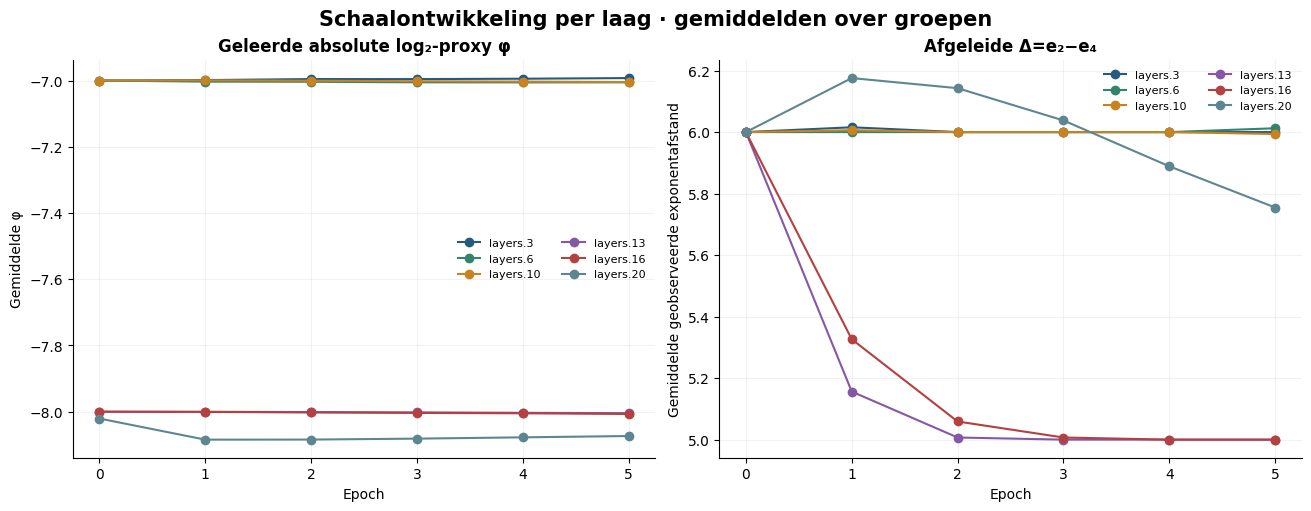

,layer,Groepen,phi_min,phi_gemiddeld,phi_max,E2_exponent_min,E2_exponent_max,geobserveerde_delta_min,geobserveerde_delta_max
0,layers.3,64,-7.42225,-6.99259,-6.50103,-7,-7,6,6
1,layers.6,80,-7.48679,-7.00542,-6.49745,-7,-6,6,7
2,layers.10,160,-7.50064,-7.00449,-6.56202,-8,-7,5,6
3,layers.13,288,-8.42168,-8.00444,-7.50187,-8,-8,5,5
4,layers.16,288,-8.50279,-8.00687,-7.50387,-9,-8,4,6
5,layers.20,3200,-9.42630,-8.07347,-7.47179,-9,-7,4,8


In [27]:
fig = h.plot_scale_by_layer(run)
figures["05_schalen_per_laag"] = fig
display(fig)
plt.close(fig)
display(h.scale_layer_table(run).round(5))

### Schaalveranderingen en gradientdiagnostiek

Links tellen we groepen waarvan de **opgeslagen waarde tussen twee opeenvolgende epochs** veranderde. Een groep die tussendoor heen en terug wisselde kan daar onzichtbaar blijven. Rechts staan daarom ook de tijdens de updates gemeten E2-wissels, inclusief terugwissels.

Een niet-nul proxyupdate hoeft niet meteen tot een andere harde exponent te leiden. Ook het omgekeerde geldt: een kleine update dicht bij een afrondingsgrens kan een discrete schaalwissel veroorzaken. Dat is een eigenschap van deze lokale surrogate-optimalisatie, geen bewijs dat expliciet alle exponenten zijn onderzocht.

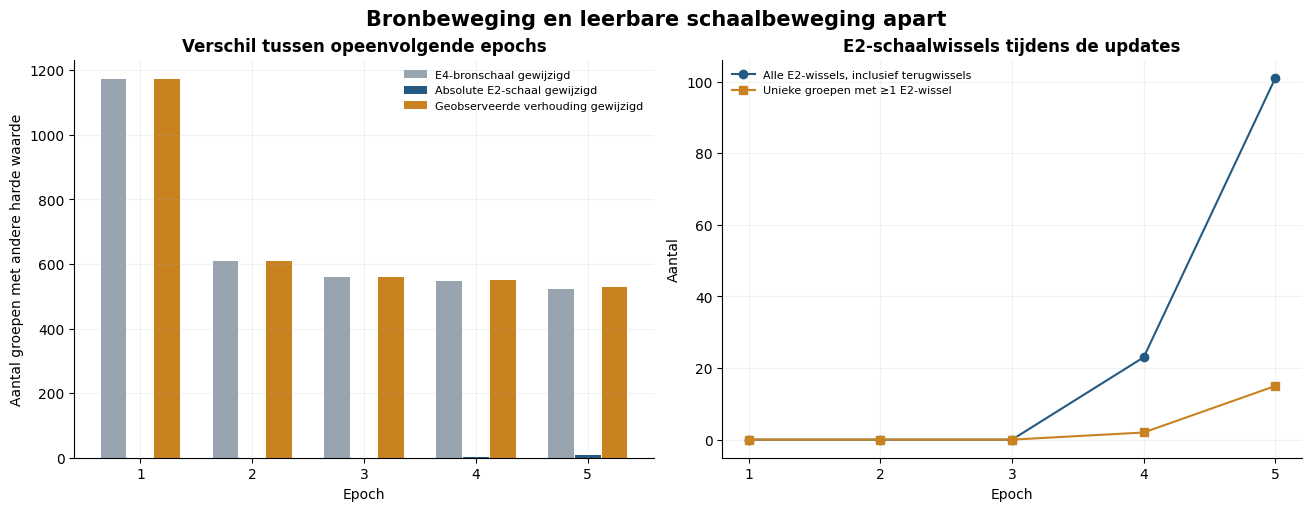

,Epoch,E4-bronschaal gewijzigd,Absolute E2-schaal gewijzigd,Geobserveerde verhouding gewijzigd
0,1,1173,0,1173
1,2,609,0,609
2,3,559,0,559
3,4,548,1,549
4,5,521,9,530


In [28]:
fig = h.plot_scale_changes(run)
figures["06_bron_en_e2_veranderingen"] = fig
display(fig)
plt.close(fig)
display(h.source_change_table(run))

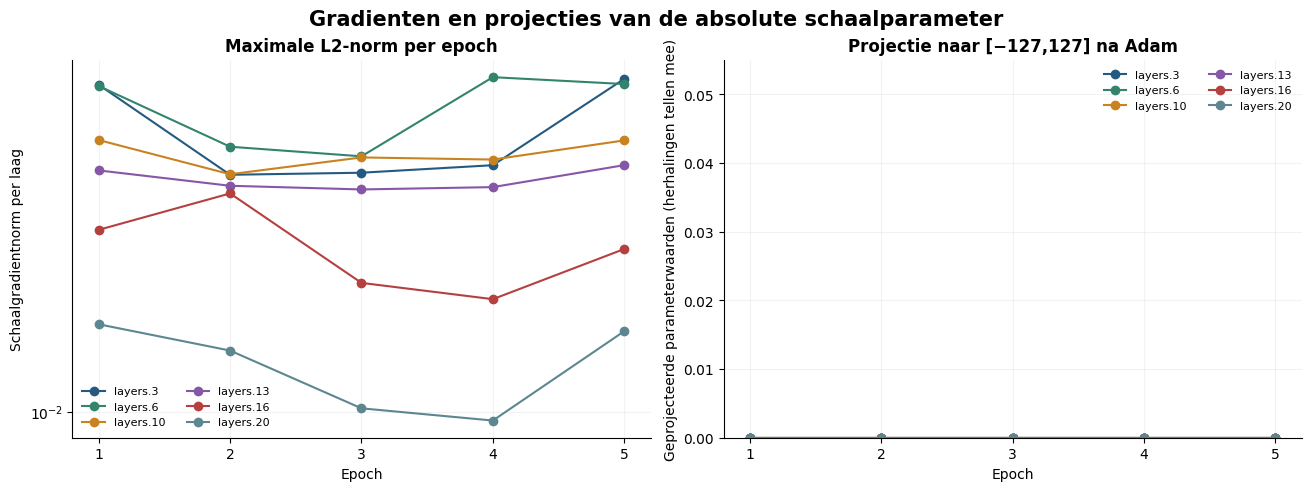

In [29]:
fig = h.plot_scale_gradients(run)
figures["07_gradient_en_projectie"] = fig
display(fig)
plt.close(fig)

## 4. Opslagkosten: wat kost de onafhankelijke schaal?

Per groep blijft één E4M3-broncode per gewichtspositie opgeslagen. Alle modi worden daaruit afgeleid. Alleen de schaalinformatie verschilt:

- **Vaste ×64:** één E4-schaalbyte; de E2-schaal wordt afgeleid.
- **Tien relatieve keuzes:** één E4-schaalbyte + vier bits keuze-informatie.
- **Onafhankelijke E2-schaal:** één E4-schaalbyte + één absolute E2-schaalbyte. E2M3 en E2M1 delen die tweede byte.

Bij 4.080 groepen is dit **4.080 bytes extra tegenover vaste ×64** en **2.040 bytes extra tegenover tien relatieve keuzes**. Beide schaalbanken samen kosten 0,5 bit per B32-positie; de eerste E4-bank is daarin meegeteld.

De onderstaande payloadberekening geldt voor de **zes MX-lagen inclusief groepspadding**. Zij sluit FP32-randlagen, BN-banken, bestandscontainerheaders, activaties en frameworkgeheugen uit. De training behoudt 4.080 FP32-proxies; proxy + gradient + twee Adam-momenten tellen analytisch 65.280 bytes, net als bij de tienkeuzemethode. Adam-stapmetadata en tijdelijke tensors vallen daarbuiten.

Deze getallen zijn **opslagberekeningen**, geen meting van geheugenverkeer, latency of energie. Hoeveel bytes bij precisiewissels werkelijk moeten worden opgehaald hangt ook van het opslag- en cachebeleid af; deze pilot meet dat niet.

,Variant,Groepen,E4-schaalbytes,Extra schaal/keuzebytes,Totaal schaalinformatie [bytes],Schaalinformatie [bit per B32-positie],"E4-codes + schaalinformatie, zes MX-lagen [bytes]",Extra training: proxy+grad+Adam [bytes]
0,Vaste ×64,4080,4080,0,4080,0.250,134640,0
1,10 relatieve keuzes,4080,4080,2040,6120,0.375,136680,65280
2,Onafhankelijke E2-schaal,4080,4080,4080,8160,0.500,138720,65280


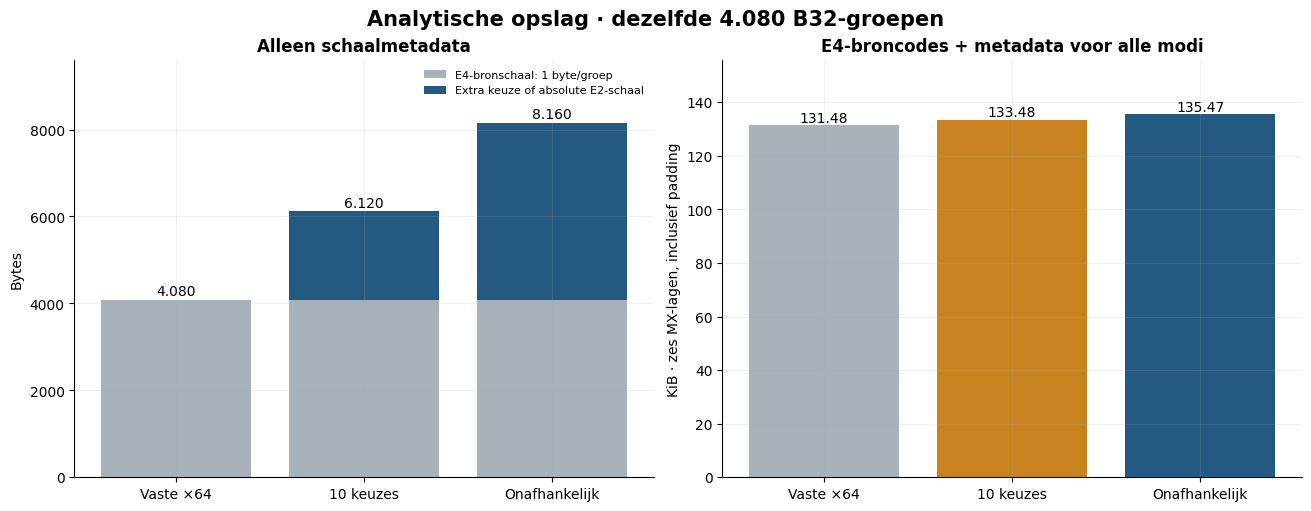

In [30]:
display(h.storage_cost_table(run))
fig = h.plot_storage_cost(run)
figures["08_opslagkosten"] = fig
display(fig)
plt.close(fig)

### Opgeslagen modelrepresentaties

De runner controleert de afgeleide gewichten tegen dezelfde live trainingsroute. Compacte bronexports bewaren de E4-codes en absolute lagere schaalbytes; zij bevatten geen masters van de zes MX-lagen en geen FP32-schaalproxies. Hervatbare trainingscheckpoints bewaren die FP32-toestand wel.

De tabel hieronder vermeldt **geserialiseerde containerbytes**, die ook hulpstaat en bestandsstructuur bevatten. Die zijn niet gelijk aan de theoretische schaalpayload uit de voorgaande grafiek. De exacte gewichtscontrole voert geen extra volledige testset-evaluatie uit.

In [31]:
display(h.export_table(run))

,Rol,Epoch,Precisie,Bestand,Containerbytes,Gewichten exact gereconstrueerd,MX-masters afwezig,FP32-schaalproxy afwezig,Afgeleid uit opgeslagen bron,Masters gelezen bij afleiding,Bron-SHA256
0,best_E4M3_test,5,E4M3,mx_source_MXFP8_E4M3_best.pt,202457,True,True,True,False,False,92c5481533910920ddb33ae13843a6652b6847ad3dd674...
1,best_E4M3_test,5,E2M3,mx_derived_MXFP6_E2M3_best.pt,170521,True,True,True,True,False,92c5481533910920ddb33ae13843a6652b6847ad3dd674...
2,best_E4M3_test,5,E2M1,mx_derived_MXFP4_E2M1_best.pt,137881,True,True,True,True,False,92c5481533910920ddb33ae13843a6652b6847ad3dd674...
3,last_epoch,5,E4M3,mx_source_MXFP8_E4M3_last.pt,202457,True,True,True,False,False,92c5481533910920ddb33ae13843a6652b6847ad3dd674...
4,last_epoch,5,E2M3,mx_derived_MXFP6_E2M3_last.pt,170521,True,True,True,True,False,92c5481533910920ddb33ae13843a6652b6847ad3dd674...
5,last_epoch,5,E2M1,mx_derived_MXFP4_E2M1_last.pt,137881,True,True,True,True,False,92c5481533910920ddb33ae13843a6652b6847ad3dd674...


## 5. Gemeten pilotduur en uitvoerbaarheid

Alleen werkelijk afgeronde epochs tellen als meting. Een eventueel 100-epochtotaal is een projectie voor een latere nieuwe training vanaf epoch0, met het oorspronkelijke LR-schema. Dit pakket zelf stopt na maximaal vijf epochs.

**Gemeten:** 5.60 minuten voor 5 complete epochs, inclusief train, test en checkpoints. **Projectie voor een nieuwe 100-epochrun:** 1.87 uur; dit is geen gemeten 100-epochtijd en geen resterende looptijd.

Voorbereiding van data, installatie en uiteindelijke rapportexport vallen buiten de epochtijden. De pilot meet de latere LR-overgangen en langdurige thermische belasting niet. Een kleinere of grotere geobserveerde tijd wordt daarom niet meteen aan schaalparametrisatie toegeschreven.

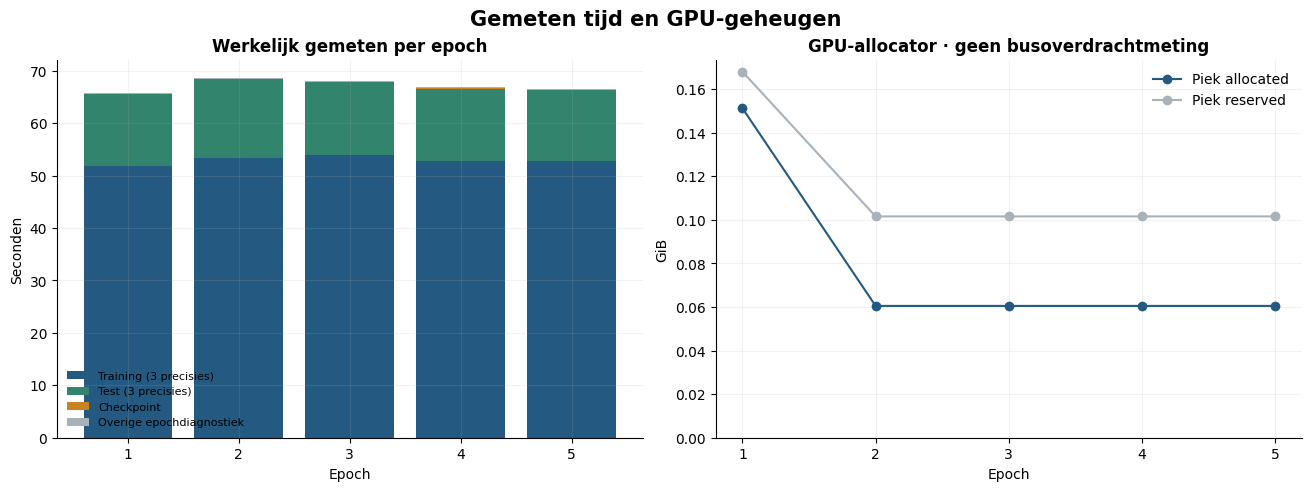

In [32]:
display(Markdown(h.timing_markdown(run)))
fig = h.plot_timing(run)
figures["09_tijd_en_gpugeheugen"] = fig
display(fig)
plt.close(fig)

## 6. Controles, herkomst en interpretatie

**Wat deze pilot kan aantonen:** technische uitvoerbaarheid, eindige gradients en optimizerstaat, behoud van de bittruncatieroute, daadwerkelijk leerbare absolute E2-schalen, en het vroege accuracyverloop.

**Wat zij niet aantoont:** betere eindaccuracy op epoch100, onafhankelijkheid van initialisatie, statistische significantie van kleine verschillen, of een hardwareversnelling. Een eigen E2-schaal betekent hier onafhankelijkheid van de actuele E4-**schaal**, terwijl de lagere elementcodes bewust uit de E4-bron blijven komen.

De codebestanden en de gelezen meetbestanden vormen de primaire bronnen voor deze notebook. Historische referenties worden via hun `REFERENCE.json` en de daarin opgenomen hashes gecontroleerd. Verschillen in de oude vaste referentie kunnen niet op identieke samplevolgorde worden nagekeken omdat de bijbehorende volledige history hier niet meegeleverd is. De onderstaande audit maakt ontbrekende of conflicterende informatie zichtbaar.

In [33]:
display(h.audit_table(run))
display(h.reference_table(run))
display(h.diagnostics_table(run))

,Controle,Opgeslagen resultaat / analyse
0,Rapportstatus,PASS
1,Metrics consistent met geschiedenis,True
2,Schaalstaten en bitexponenten consistent,True
3,Checkpointselectie gecontroleerd,True
4,Historische referenties geverifieerd,True
5,FP32-masters en Adam-momenten,True
6,Eén E4-bron per laag en minibatch,True
7,E2M1-schaal identiek aan E2M3,True
8,Cache leeg vóór optimizerupdates,True
9,Evaluatie zonder optimizerupdates,True


,Referentie,Bronrun,Gebruikt venster,Bestand,Marker SHA256,Vergelijking met nieuwe run gevalideerd
0,10 relatieve keuzes · start ×64,C:\Users\renzo\master-thesis-mx\mx_runs\mx_tri...,epochs 1–5 (of dezelfde kortere nieuwe run),C:\Users\renzo\master-thesis-mx\mx_runs\mx_tri...,e2df45acecccb8e56115b4d01f90b11a5f43bb4c9bfa02...,True
1,Vaste verhouding ×64,C:\Users\renzo\master-thesis-mx\mx_runs\mx_tri...,epochs 1–5 (of dezelfde kortere nieuwe run),C:\Users\renzo\master-thesis-mx\mx_runs\mx_tri...,a323762894db83b15af10e79a8aff0128c50f7946805a0...,True


,Niveau,Melding
0,RUNWAARSCHUWING,The argument 'device' of Tensor.pin_memory() i...
1,RUNWAARSCHUWING,The argument 'device' of Tensor.is_pinned() is...


## 7. Optioneel: figuren bewaren

Standaard blijft deze stap uitgeschakeld. Met `SAVE_FIGURES = True` komen PNG- en PDF-bestanden plus een herkomstbestand in een nieuwe map naast de resultaten. Ruwe data en eerdere figuren worden niet overschreven.

In [34]:
if SAVE_FIGURES:
    saved = h.save_figures(figures, run)
    print("Nieuwe figurenmap:", saved)
else:
    print("Figuren alleen weergegeven; niets opgeslagen.")

Figuren alleen weergegeven; niets opgeslagen.
